    Single allele groupped structue models.

In [1]:
import pomegranate.io
from pomegranate import *

In [2]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


In [3]:
import training_parameters
from peptides_utils import defineClass, defineOrganism, make_logo_for_data
from data_reading_methods import remove_unused_lengths, transform_data_to_properties_and_join_alleles, calculate_weights_based_on_length_counts

# 1. Read data

In [4]:
hmm_params = training_parameters.ExperimentParams(experiment_name="split_mixmhc")
hmm_params.model_training_params = training_parameters.SimpleModelClassIIParamsMixMHC()
hmm_params.data_scenario_params = training_parameters.MixMHCpredDataParams()
hmm_params.data_scenario_params.mixmhc_mixture_name = hmm_params.data_scenario_params.extra['mixed_samples'][0]

In [5]:
model_training_params = hmm_params.model_training_params
model_training_params.num_runs = 10

In [6]:
from data_reading_methods import get_available_alleles, get_train_test_data, join_dicts

per_allele_per_kfold_per_length_binders_train, \
per_allele_per_kfold_per_length_binders_test, additional_data = get_train_test_data(hmm_params)

PARSED_ALLELES = list(per_allele_per_kfold_per_length_binders_train.keys())

print(sorted(PARSED_ALLELES))

Will read files from the folder /storage1/fs1/martyomov/Active/IndividualBackUps/denisk/data/binding_data/MixMHC2pred_2023/train_data/external_studies.csv
Index(['Peptide', 'pepL', 'geneName', 'Nterm', 'Cterm', 'Sample_IDs', 'Allele',
       'multiSpec', 'Core', 'CoreOffset'],
      dtype='object')
Total table length 916677
Filtered for given mixture 1011
['d_mixMHC_DRB1_03_01_DRB3_01_01']


In [7]:
model_training_params.lengths_to_use = list(set.intersection(set(model_training_params.lengths_to_use), set(per_allele_per_kfold_per_length_binders_train[PARSED_ALLELES[0]][0].keys())))

# 2. Prepare data and weithgs for training

In [8]:
df = additional_data[0][list(additional_data[0].keys())[0]]

In [9]:
list(additional_data[0].keys())

['d_mixMHC_DRB1_03_01_DRB3_01_01']

In [10]:
df.mixmhc_predicted_mixed_alleles.value_counts()

mixmhc_predicted_mixed_alleles
DRB3*01:01    338
DRB1*03:01    273
Name: count, dtype: int64

In [11]:
current_mix = PARSED_ALLELES[0]
[ item for item in PARSED_ALLELES if item in [current_mix]]

['d_mixMHC_DRB1_03_01_DRB3_01_01']

In [12]:
model_training_params: training_parameters.ModelTrainingParams = hmm_params.model_training_params
#model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['HLA-DRB1*04:01']]
current_mix = PARSED_ALLELES[0]
model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in [current_mix]]
t = remove_unused_lengths(per_allele_per_kfold_per_length_binders_train, experiment_params=hmm_params)

In [13]:
model_training_params: training_parameters.ModelTrainingParams = hmm_params.model_training_params
#model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['HLA-DRB1*04:01']]
current_mix = PARSED_ALLELES[0]
model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in [current_mix]]
#model_training_params.alleles_to_use = [ item for item in PARSED_ALLELES if item in ['decoy-allele-78']]
# remove unused lengths (used are specified in ModelTrainingParams.model_training_params
per_allele_per_kfold_per_length_binders_train = remove_unused_lengths(per_allele_per_kfold_per_length_binders_train, experiment_params=hmm_params)
per_allele_per_kfold_per_length_binders_test = remove_unused_lengths(per_allele_per_kfold_per_length_binders_test,experiment_params=hmm_params)

# transform to properties if needed and join multiple alleles
train_data, test_data, NEW_ALLELES, \
old_train_data, old_test_data, OLD_ALLELES = transform_data_to_properties_and_join_alleles(
    per_allele_per_kfold_per_length_binders_train,
    per_allele_per_kfold_per_length_binders_test,
    hmm_params.model_training_params
)
# Calculate weights for the training data based on peptide couns/lengths for unmerged data
train_data_weigths = calculate_weights_based_on_length_counts(old_train_data, experiment_params=hmm_params)

d_mixMHC_DRB1_03_01_DRB3_01_01
Length 12: d_mixMHC_DRB1_03_01_DRB3_01_01 - 12 
Length 13: d_mixMHC_DRB1_03_01_DRB3_01_01 - 45 
Length 14: d_mixMHC_DRB1_03_01_DRB3_01_01 - 97 
Length 15: d_mixMHC_DRB1_03_01_DRB3_01_01 - 156 
Length 16: d_mixMHC_DRB1_03_01_DRB3_01_01 - 186 
Length 17: d_mixMHC_DRB1_03_01_DRB3_01_01 - 159 
Length 18: d_mixMHC_DRB1_03_01_DRB3_01_01 - 100 
Length 19: d_mixMHC_DRB1_03_01_DRB3_01_01 - 65 
Length 20: d_mixMHC_DRB1_03_01_DRB3_01_01 - 47 


## Check: Motif for train data

In [14]:
train_data.keys()

dict_keys(['d_mixMHC_DRB1_03_01_DRB3_01_01'])

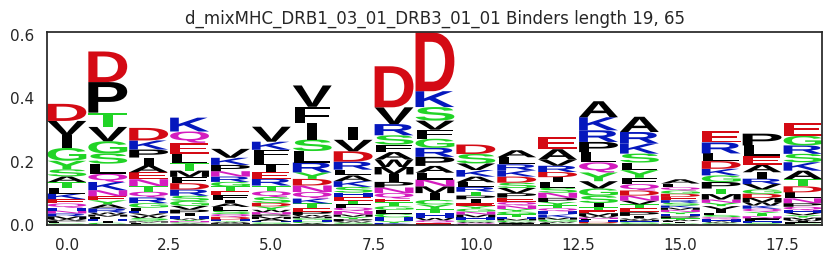

In [15]:
import matplotlib.pyplot as plt
from peptides_utils import make_logo_for_data
target_allele = hmm_params.model_training_params.alleles_to_use[0]
target_length = hmm_params.model_training_params.lengths_to_use[2]
peptides = train_data[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# 3. Models

In [16]:
import random

random.seed(10)

from hmm_logic_methods import train_model_prepared,  \
    train_model_batched, save_model, \
    add_more_states_and_reset_transitions, \
    build_model_based_on_params, \
    prepare_multiple_models, train_multiple_models, \
reorder_models_by_score_and_flatten_to_by_name_list, hierarchically_train_splited_models
from hmm_visualization_methods import *

## Check generate sample model to ensure that it is looking like we want

In [17]:
prepared_model = build_model_based_on_params(hmm_params.model_training_params, verbose=True)

with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

plot_distributions_for_states(prepared_model,"test", horizontal=False,
                              discrete = hmm_params.model_training_params.aa_labels_training,
                              initial_params = hmm_params.model_training_params.initial_params)
make_pyviz_graph(prepared_model, "test", precision=3)

start cycles added 1
end cycles added 1
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]


<class 'pyvis.network.Network'> |N|=13 |E|=16

## Prepare and train models

In [19]:
%%time
#prepare models
per_allele_per_run_per_split_prepared_models = prepare_multiple_models(hmm_params)
#do training

result_models, result_histories =  train_multiple_models(
    prepared_models=per_allele_per_run_per_split_prepared_models,
    train_data=train_data,
    test_data=test_data,
    train_data_weigths=train_data_weigths,
    experiment_params=hmm_params,
    subfolder_to_safe_result="root")

Allele d_mixMHC_DRB1_03_01_DRB3_01_01: root[0000] Model root[0000]_run-7-st-v-alg-40-min_iters-12-20_model-d_mixMHC_DRB1_03_01_DRB3_01_01-0
Get viterbi paths for each peptide...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 867/867 [00:00<00:00, 13586.12it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 867 


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 867/867 [00:00<00:00, 15093.94it/s]


transform to info matrix
Will calculate sliding window sum for f17 positions with original vector of size 25
calculate shifts for fragments of length 9
Seems to be shift to the right, since there is an alignment hit outside the model frame
Shifting model frame to the best pick rightwise
shape of new matrix f(9, 20)
will try to set probabilities from the matrix
finished model construction
some models had shifts, we will try one more iteration of training
root[0001] Model root[0001]_run-7-st-v-alg-40-min_iters-12-20_model-d_mixMHC_DRB1_03_01_DRB3_01_01-0
Get viterbi paths for each peptide...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 867/867 [00:00<00:00, 13627.46it/s]


... (31 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 867/867 [00:00<00:00, 21263.12it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 867 


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 867/867 [00:00<00:00, 22200.89it/s]


transform to info matrix
Will calculate sliding window sum for f17 positions with original vector of size 25
calculate shifts for fragments of length 9
Seems to be shift to the right, since there is an alignment hit outside the model frame
Shifting model frame to the best pick rightwise
shape of new matrix f(9, 20)
will try to set probabilities from the matrix
finished model construction
some models had shifts, we will try one more iteration of training
 
CPU times: user 48.2 s, sys: 407 ms, total: 48.6 s
Wall time: 49.7 s


In [20]:
per_name_models, per_name_histories, original_alelle_sortings = reorder_models_by_score_and_flatten_to_by_name_list(histories=result_histories,
                                                                models=result_models, experiment_params=hmm_params,subfolder_to_safe_result="root" )
save_all_visualization_results(per_name_models, per_name_histories, experiment_params=hmm_params, subfolder_to_safe_result="root", subset=10)


ModelGraph
0 1 2 3 4 5 6 7 8 9 
Distributions
0 1 2 3 4 5 6 7 8 9 
PyViz


## Check how models align the data

Model root[0001]_run-7-st-v-alg-40-min_iters-9-20_model-d_mixMHC_DRB1_03_01-0
Get viterbi paths for each peptide...


100%|███████████████████████████████████████████████████████████████████████████████████| 2156/2156 [00:00<00:00, 20983.25it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 2156 


100%|███████████████████████████████████████████████████████████████████████████████████| 2156/2156 [00:00<00:00, 23634.27it/s]


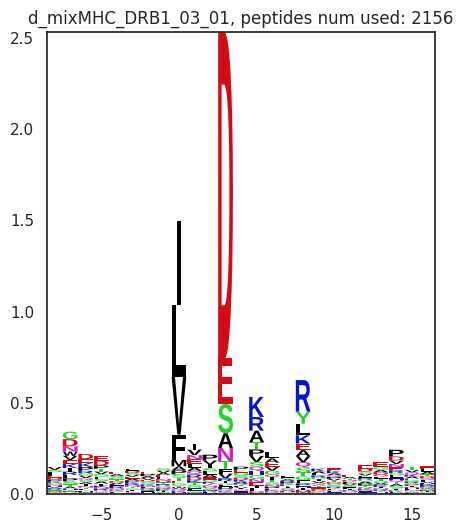

In [19]:
import importlib
import hmm_logic_methods
import hmm_visualization_methods
import logomaker
from peptides_utils import get_frequencies
hmm_logic_methods= importlib.reload(hmm_logic_methods)
hmm_logic_methods= importlib.reload(hmm_visualization_methods)
from hmm_logic_methods import check_model_alignment, init_distribution
allele_data_df = join_dicts(train_data)[PARSED_ALLELES[0]]
allele_name = PARSED_ALLELES[0].replace('-', '_').replace('*', '_').replace(':', '_')

info_matrix, _, fig = check_model_alignment(per_name_models[list(per_name_models.keys())[1]], allele_data_df, allele_name)
filename=f"{allele_name}-split-root-example_of_alignment.svg"
path_to_save_pictures = f"{hmm_params.experiment_result_data_path}"
save_figure_to_svg(fig, dir=path_to_save_pictures, filename=f"{filename}.svg")


For information content 2 will be summarized
check how many models we added at the end: defaultdict(<class 'int'>, {'d_mixMHC_DRB1_03_01': 2})
info calculated  {'d_mixMHC_DRB1_03_01': 0.7257210806560302}
For root 10 models passed the info filter out of 10


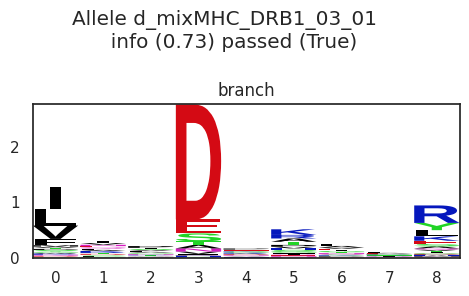

In [21]:
from hmm_logic_methods import get_information_content_estimation_for_models
statistics_estimate_models_fraction = model_training_params.statistics_estimate_model_fraction

name_to_info_value, allele_to_info_matrix, allele_to_info_value = get_information_content_estimation_for_models(per_name_models, models_fraction=statistics_estimate_models_fraction)
model_name_to_allele = {
    model_name : f"{model_name.split('-')[-2]}" for model_name in per_name_models.keys()
}
path_to_save_pictures = f"{hmm_params.experiment_result_data_path}"
info_threshold = model_training_params.trash_model_information_threshold
passed_filter = {key for key, info_value in name_to_info_value.items() if info_value > info_threshold}
print(f"For root {len(passed_filter)} models passed the info filter out of {len(per_name_models)}")
for allele_name in allele_to_info_matrix.keys():
    info_value =allele_to_info_value[allele_name]
    passed = info_value > info_threshold
    main_title = f"Allele {allele_name} \n  info ({np.round(info_value,2)}) passed ({passed})"
    filename=f"{allele_name}-split-root.svg"
    fig, ax = plt.subplots(ncols      =1, nrows=1, figsize=(5, 3))
    ww_logo = logomaker.Logo(allele_to_info_matrix[allele_name], font_name='Liberation Sans Narrow', flip_below=True,
                             ax=ax)
    ww_logo.ax.set_title(f"branch")
    fig.suptitle(main_title)
    plt.tight_layout()
    save_figure_to_svg(fig, dir=path_to_save_pictures, filename=f"{filename}.svg")
    plt.close(fig)
fig

In [22]:
path_to_save_pictures

'/storage1/fs1/martyomov/Active/IndividualBackUps/denisk/mhcprediction/MHC_predictor/experiments/core_identification_simple_model_enrichment/experiment_results/split_mixmhc/MixMHCpred'

In [23]:
train_data.keys()

dict_keys(['d_mixMHC_DRB1_03_01'])

# Splitting

iteration br1
Starting split br1
Number of models used for this split is 2
split is 1186/970
Allele d_mixMHC_DRB1_03_01: br11[0000] Model br11[0000]_run-7-st-v-alg-40-min_iters-9-20_model-d_mixMHC_DRB1_03_01-0
Get viterbi paths for each peptide...


100%|███████████████████████████████████████████████████████████████████████████████████| 1186/1186 [00:00<00:00, 21446.19it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 1186 


100%|███████████████████████████████████████████████████████████████████████████████████| 1186/1186 [00:00<00:00, 23554.47it/s]


transform to info matrix
Will calculate sliding window sum for f17 positions with original vector of size 25
calculate shifts for fragments of length 9
br11[0001] Model br11[0001]_run-7-st-v-alg-40-min_iters-9-20_model-d_mixMHC_DRB1_03_01-0
Get viterbi paths for each peptide...


100%|███████████████████████████████████████████████████████████████████████████████████| 1186/1186 [00:00<00:00, 21553.89it/s]


... (233 outputs left out)

100%|█████████████████████████████████████████████████████████████████████████████████████| 887/887 [00:00<00:00, 20082.63it/s]


transform to info matrix
Will calculate sliding window sum for f17 positions with original vector of size 25
calculate shifts for fragments of length 9
 

ModelGraph
0 1 2 3 4 5 6 7 8 9 
Distributions
0 1 2 3 4 5 6 7 8 9 
PyViz

ModelGraph
0 1 2 3 4 5 6 7 8 9 
Distributions
0 1 2 3 4 5 6 7 8 9 
PyViz
Now estimating this split result...
For information content 2 will be summarized
check how many models we added at the end: defaultdict(<class 'int'>, {'d_mixMHC_DRB1_03_01': 2})
info calculated  {'d_mixMHC_DRB1_03_01': 0.8852704298161664}
For information content 2 will be summarized
check how many models we added at the end: defaultdict(<class 'int'>, {'d_mixMHC_DRB1_03_01': 2})
info calculated  {'d_mixMHC_DRB1_03_01': 0.6201429162038823}
geting the average model matrix
check how many models we added at the end: defaultdict(<class 'int'>, {'d_mixMHC_DRB1_03_01': 2})
geting the average model matrix
check how many models we added at the end: defaultdict(<class 'int'>, {'d_mixMHC_DRB1_03_01'

/storage1/fs1/martyomov/Active/snakemake_caches/denisk/.conda/envs/pomegranate/lib/python3.9/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/storage1/fs1/martyomov/Active/snakemake_caches/denisk/.conda/envs/pomegranate/lib/python3.9/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


this method supports 1 split for now
diagnostic method finished
CPU times: user 6min 26s, sys: 1min 8s, total: 7min 35s
Wall time: 5min 12s


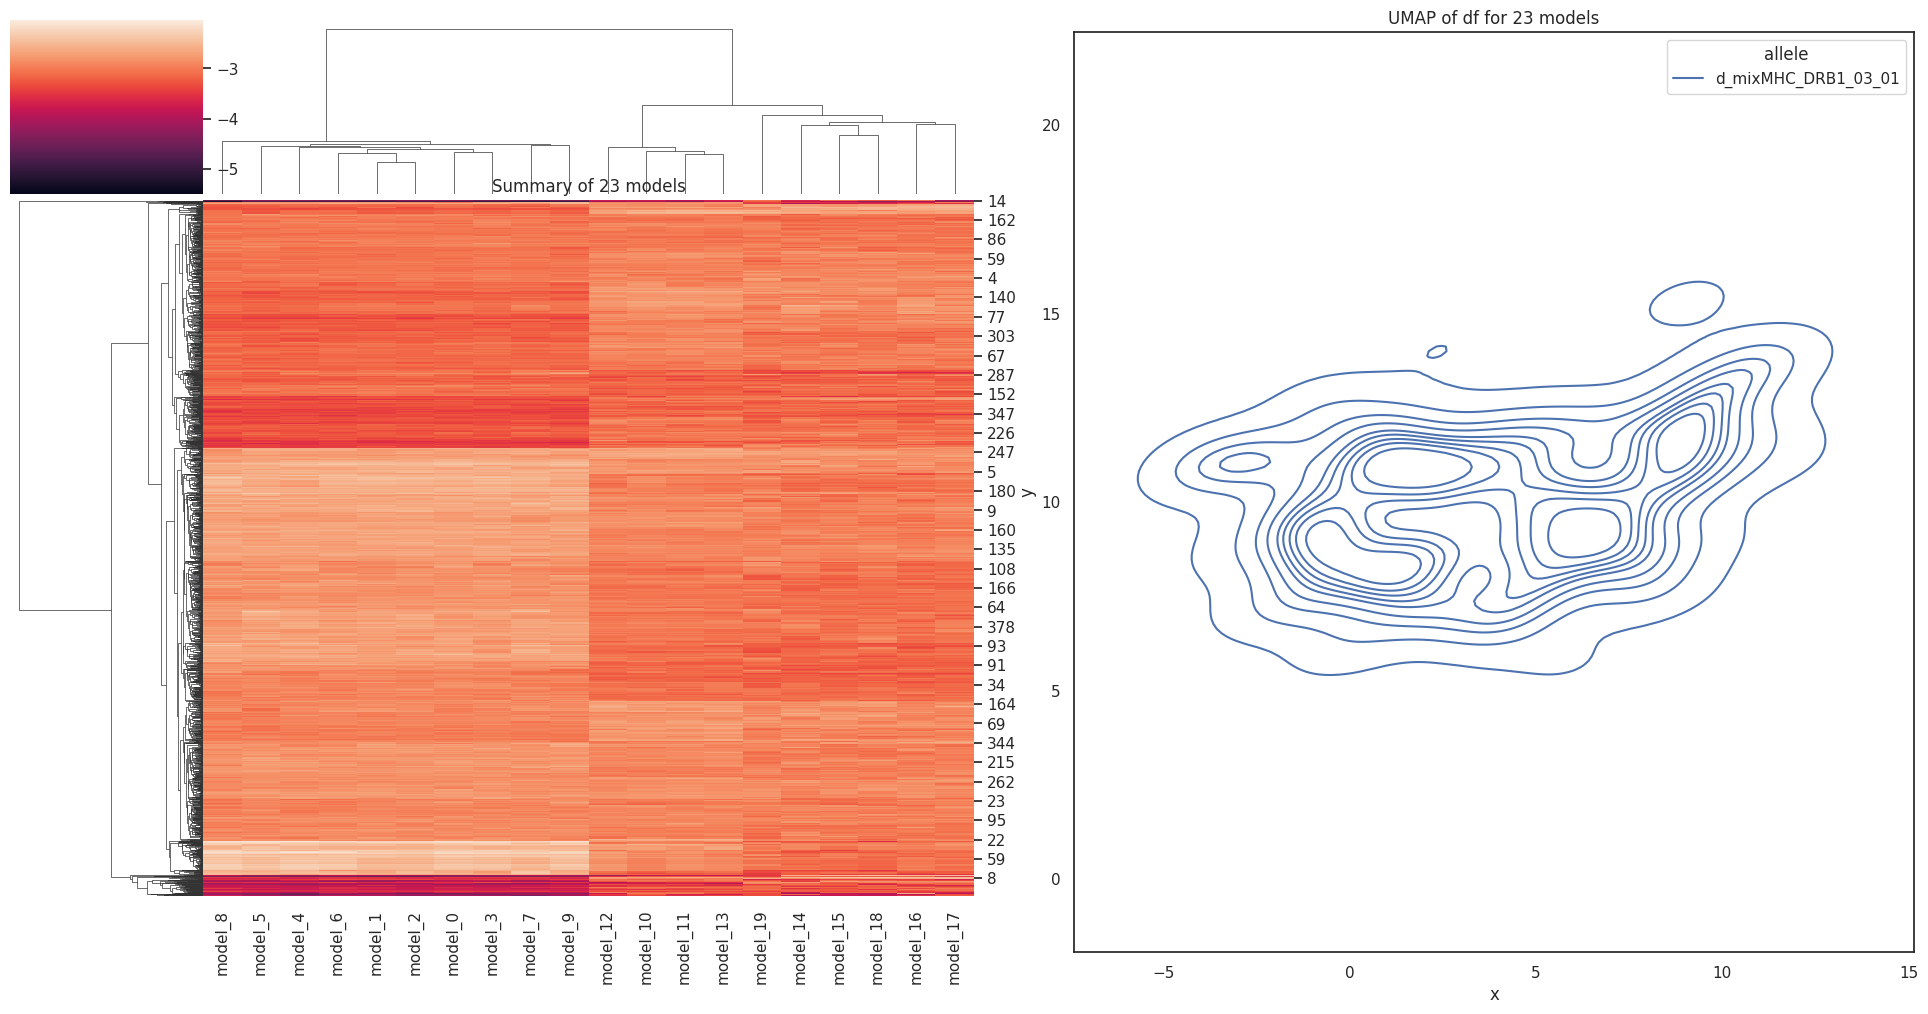

In [24]:
%%time
import sys
#orig_std = sys.stdout
with open('out_split.txt', 'w') as f:
   # sys.stdout = f
    models, split_pictures = hierarchically_train_splited_models(per_name_models=per_name_models,
                                        train_data=train_data,
                                        test_data=test_data,
                                        additional_data=additional_data,
                                        experiment_params=hmm_params,
                                        total_layers_to_do=1)
#sys.stdout = orig_std

In [25]:
models.keys()

dict_keys(['br11', 'br12'])

Model br12[0003]_run-7-st-v-alg-40-min_iters-9-20_model-d_mixMHC_DRB1_03_01-0
Get viterbi paths for each peptide...


100%|███████████████████████████████████████████████████████████████████████████████████| 2156/2156 [00:00<00:00, 13243.20it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 2156 


100%|███████████████████████████████████████████████████████████████████████████████████| 2156/2156 [00:00<00:00, 14209.69it/s]


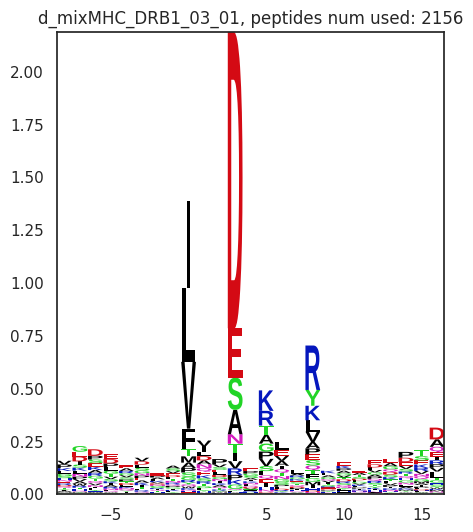

In [31]:
allele_data_df = join_dicts(train_data)[PARSED_ALLELES[0]]
allele_name = PARSED_ALLELES[0].replace('-', '_').replace('*', '_').replace(':', '_')

current_models = models['br12']

info_matrix, _, fig = check_model_alignment(current_models[list(current_models.keys())[3]], allele_data_df, allele_name)
# filename=f"{allele_name}-split-root-example_of_alignment.svg"
# path_to_save_pictures = f"{hmm_params.experiment_result_data_path}"
# save_figure_to_svg(fig, dir=path_to_save_pictures, filename=f"{filename}.svg")
